In [1]:
# Prerequisites
import matplotlib.pyplot as plt
import numpy as np

from ponds.visualization import barplot_3D

plt.rcParams["figure.dpi"] = 150
plt.rcParams["figure.figsize"] = (10, 5)


def birdview_heatmap(
    cluster_mask,
    shift_times,
):
    shift_mask = np.full(cluster_mask.shape, np.nan)
    shift_mask[cluster_mask] = shift_times[cluster_mask]

    plt.imshow(shift_mask, origin="lower")

    # set reasonable number of ticks and map them to lat/lon values
    n_ticks = 5
    plt.xlabel("Longitude [°]")
    plt.ylabel("Latitude [°]")

    # limit axes to bounding box of finite values (no nans)
    valid = np.isfinite(shift_mask)
    if np.any(valid):
        rows, cols = np.where(valid)
        i_min, i_max = rows.min(), rows.max()
        j_min, j_max = cols.min(), cols.max()

        # set axis limits to pixel edges so imshow crops to the data window
        plt.xlim(j_min - 5, j_max + 5)
        plt.ylim(i_min - 5, i_max + 5)

        # recompute tick positions inside the cropped window
        nx_window = j_max - j_min + 1
        ny_window = i_max - i_min + 1
        x_idx = np.linspace(j_min, j_max, min(nx_window, n_ticks), dtype=int)
        y_idx = np.linspace(i_min, i_max, min(ny_window, n_ticks), dtype=int)

        plt.xticks(x_idx, [f"{v:.1f}" for v in lons[x_idx]], rotation=45)
        plt.yticks(y_idx, [f"{v:.1f}" for v in lats[y_idx]])

    plt.colorbar(label="Time offset [steps]")
    plt.show()

# Feature Correlation

By default, the shift event setup for a shift cluster is the same for every cell in the cluster. Hoewever, PONDS provides the option to correlate these shift events within a cluster. The user can choose which shift-feature is affected by this correlation when initializing the shift event. For example, when `feature_name = "central_time"` is specified, the correlation method shift the exact time-index of the shift event within a single cell back or forth, depending on the method. Other shift features like `"shift_magnitude"`, etc. can be choosen alternatively.<br>
<br>
A crucial argument of the correlation-methods is `cluster_mask`. In indicates to which grid cells in the PONDS the computed time-offsets are applied. 

## Gaussian Correlation

The Gaussian correlation method maps a 2D Gauss curve onto the shift-event time distribution. Here, the user can set the location of the peak of the Gauss-curve as well as its sigma extension in both direction. Let's say we want to correlate the `"central_time"` shift-feature. The shift event of the grid cell at the chosen center coordinates will remain at the central_time of the shift event specified in the shift-method. The shift times of the cells around it will be pushed towards the past according to the gaussian dsitribution, meaning that the shift event is happening earlier in time. Due to the discretization of the time dimension, these offsets are rounded to the nearest integer (in units of the time steps). The user can further specify the depth of the Gaussian dsitribution by setting the variable `max_offset`.

See the example below for a simple use case. We are choosing a circular shift-cluster mask and place a Gaussian correlation directly at its center (same center coordinates). This leads to a shift cluster event that moves "inwards" in time. This example could mimic the shrinking observed in Antarctic ice sheet models, where abrupt melting events are happening from season to season.

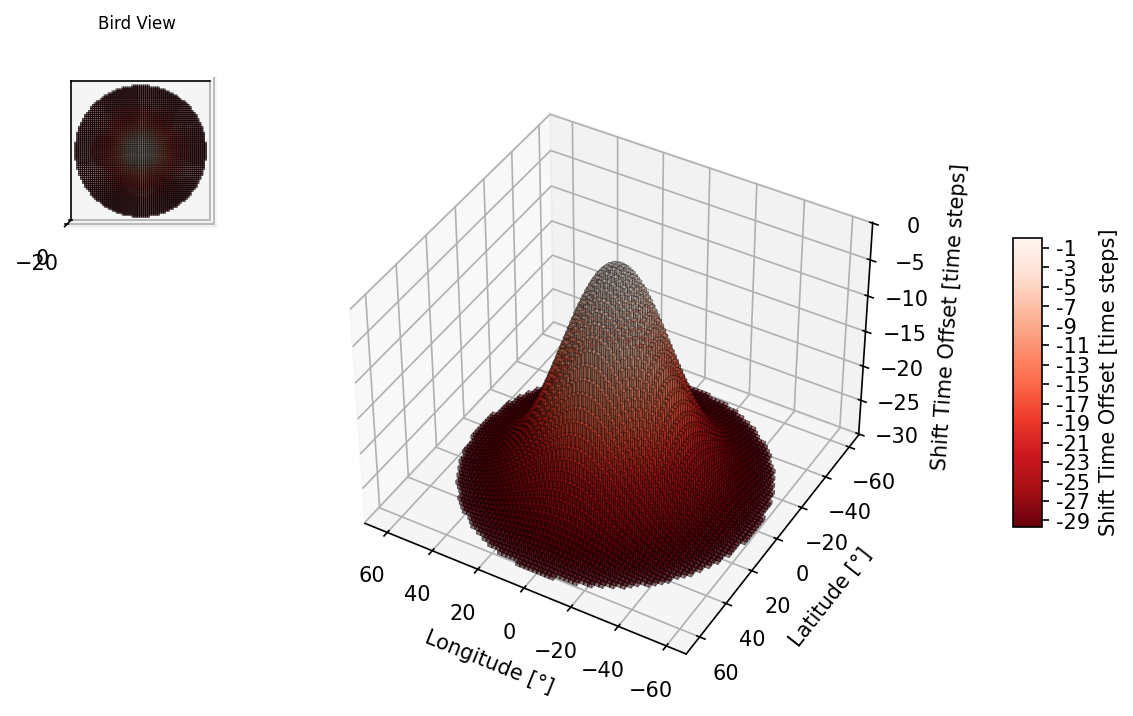

In [3]:
from ponds import ELLIPSIS, Gauss

lat_size = 101
lon_size = 201
lats = np.linspace(-90, 90, lat_size)
lons = np.linspace(-180, 180, lon_size)

# Create a mask with an ellipsis shape
cluster = ELLIPSIS(
    center_lat=0,
    center_lon=0,
    ecc_lat=60,
    ecc_lon=60,
)
cluster_mask = cluster.make_shape(lats=lats, lons=lons)

corr = Gauss(
    feature_name="central_time",
    corr_center_lat=0,  # latitude of the gaussian peak
    corr_center_lon=0,  # longitude of the gaussian peak
    sigma_lat=20,  # gauss standard deviation in latitude
    sigma_lon=20,  # gauss standard deviation in longitude
    max_offset=30,
)

shift_times = corr.make_feature_offsets(
    cluster_mask,
)

# Use an interactive backend inside Jupyter
%matplotlib inline

fig, ax = barplot_3D(
    cluster_mask,
    lons,
    lats,
    shift_times,
    alpha=0.3,
    cmap="Reds_r",
)

Now, we want to use this correlation method in an actual PONDS. Notice how in this example, we are not specifying any central coordinates for the correlation method. This is by design and shows a conventient feature of PONDS. It automatically aligns the center of the cluster shape and the center of the gaussian correlation. So even if the cluster mask is set to a random position (no central coordinates specified by the user), the correlation method is centered at the same coordinates. 

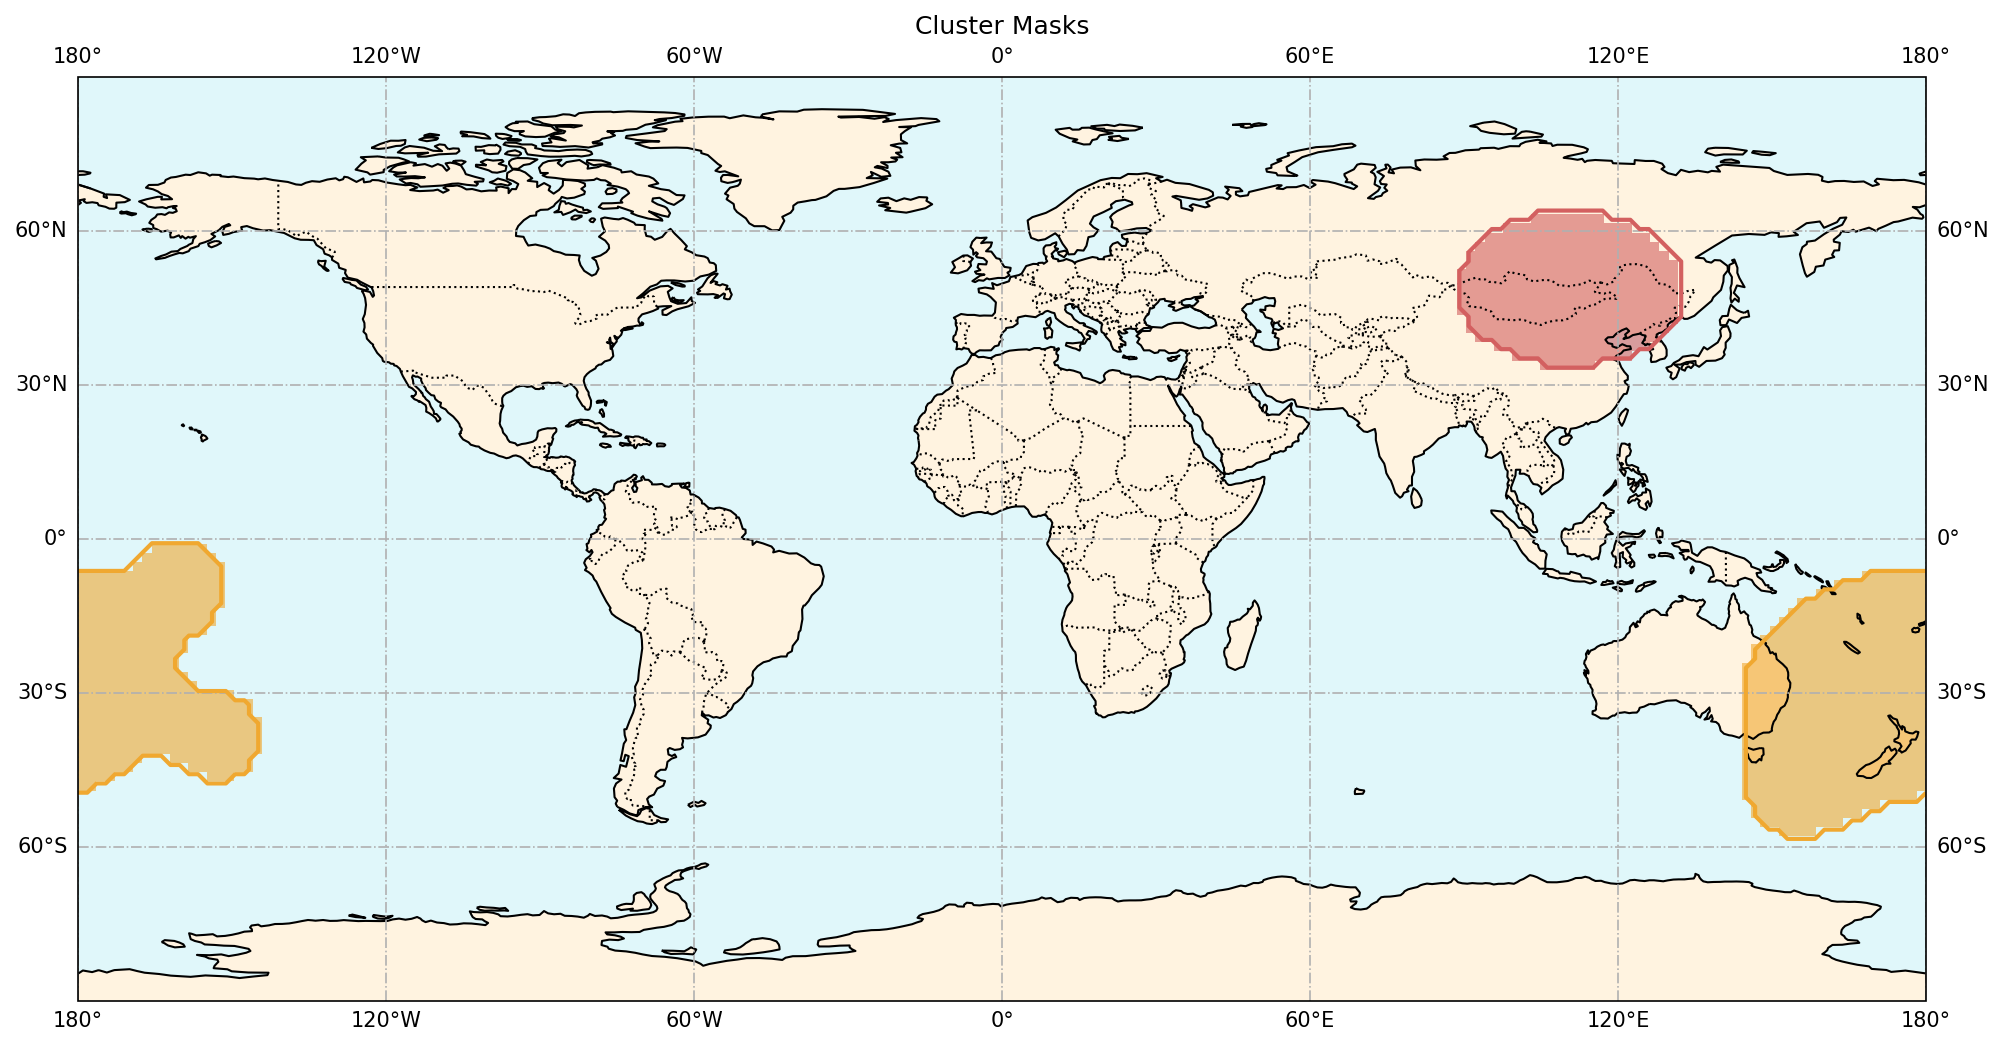

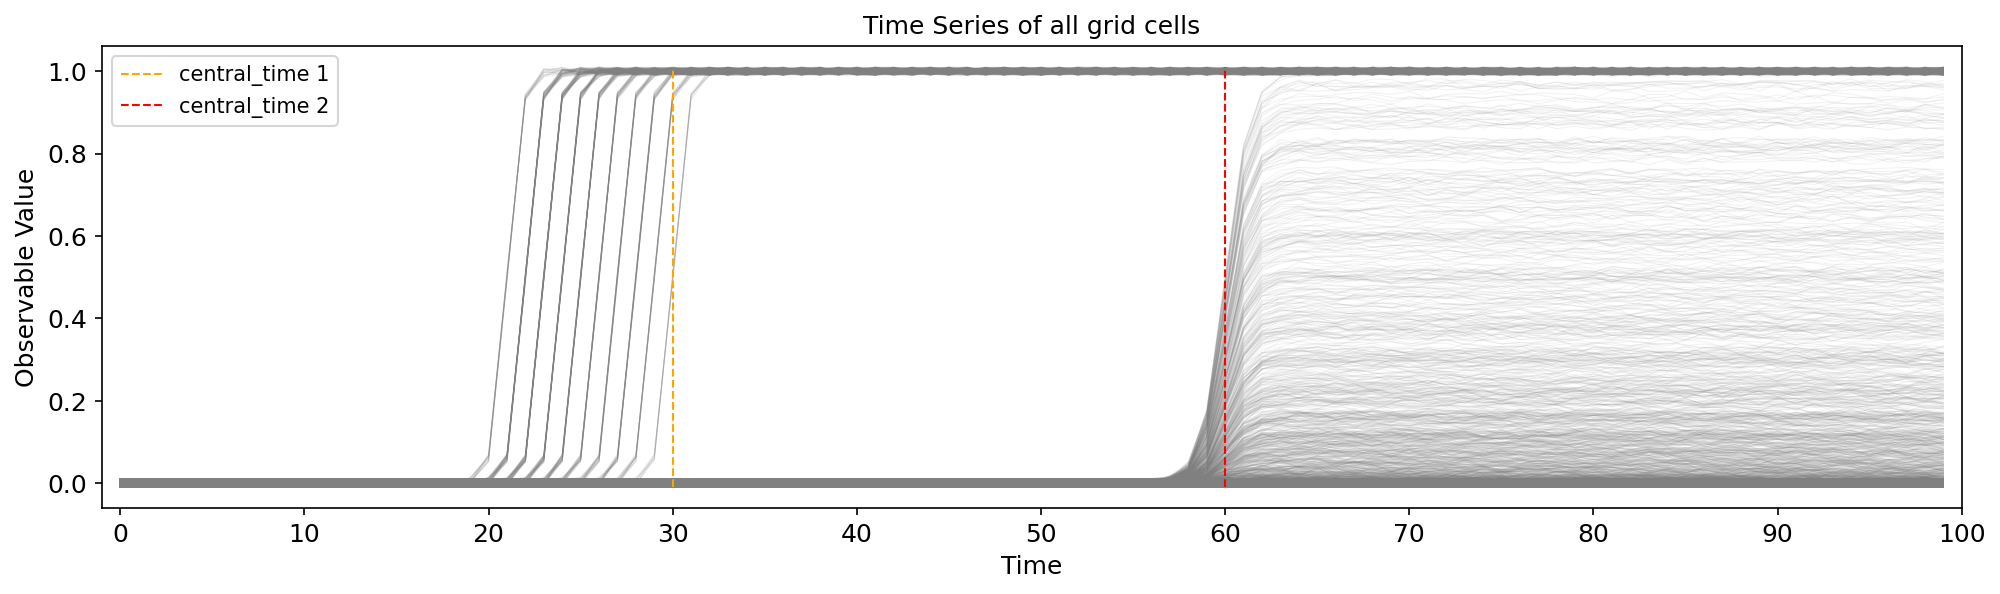

In [17]:
from ponds import PONDS, SIGMOID, BLOB, ELLIPSIS, Gauss, WhiteNoise
import numpy as np


central_time_1 = 30
shift_magnitude_1 = 1
max_offset_1 = 10
central_time_2 = 60
shift_magnitude_2 = 1
max_offset_2 = 1

pd = PONDS(
    lat_size=101,
    lon_size=201,
    time_size=100,
)

pd.add_background(
    background_method=WhiteNoise(
        magnitude=0.01,
        background_seed=1,
    )
)

pd.add_shift(
    shift_method=SIGMOID(
        central_time=central_time_1,
        shift_magnitude=shift_magnitude_1,
    ),
    shape_method=ELLIPSIS(
        shape_seed=5,
    ),
    correlation_method=Gauss(
        feature_name="central_time",
        max_offset=max_offset_1,
    ),
)

pd.add_shift(
    shift_method=SIGMOID(
        central_time=central_time_2,
        shift_magnitude=shift_magnitude_2,
    ),
    shape_method=BLOB(
        shape_seed=8,
    ),
    correlation_method=Gauss(
        feature_name="shift_magnitude",
        max_offset=max_offset_2,
    ),
)

fig1, ax1 = pd.worldmap()

fig2, ax2 = pd.plot_some_ts(
    ratio=1.0,
    alpha=0.1,
)

ax2.vlines(
    x=central_time_1,
    ymin=np.min(pd.data.ts),
    ymax=np.max(pd.data.ts),
    linestyle="--",
    linewidth=1,
    color="orange",
    label="central_time 1",
)
ax2.vlines(
    x=central_time_2,
    ymin=np.min(pd.data.ts),
    ymax=np.max(pd.data.ts),
    linestyle="--",
    linewidth=1,
    color="red",
    label="central_time 2",
)
ax2.set_title("Time Series of all grid cells")
ax2.legend(loc="upper left")

plt.show()

The second plot above shows the times series of every cell of our PONDS. In one of them, we see the shift-event correlated in shift-time and in the other, we see a correlation of the shift-magnitude. The strength of the plot lines indicate the abundance of shift events at the point in time. In the first example, we can observe many events happening around the specified `max_offset_1` before the sepcified `central_time_1`. These are the shift events happening at the edge of the cluster shapes. With passing of time, the shift-event horizon moves inwards to the center of the shift-cluster.<br>
In the second example, we can see the shift-magnitude increasing inwards to the second shift-cluster.

## Noise Correlation

Another method is to use random time-offsets, which can be used to mimic uncertainties in the shift-event time.

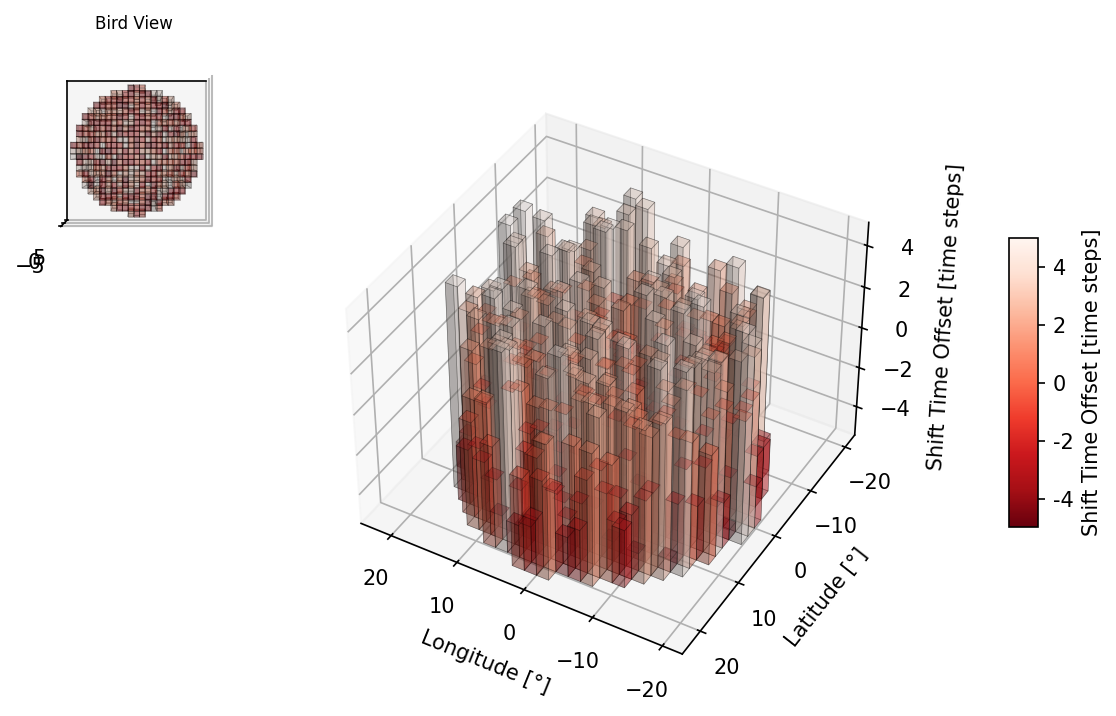

In [6]:
from ponds import ELLIPSIS, Noise

lat_size = 101
lon_size = 201
lats = np.linspace(-90, 90, lat_size)
lons = np.linspace(-180, 180, lon_size)

# Create a mask with an ellipsis shape
cluster = ELLIPSIS(
    center_lat=0,
    center_lon=0,
    ecc_lat=20,
    ecc_lon=20,
)
cluster_mask = cluster.make_shape(lats=lats, lons=lons)

corr = Noise(
    feature_name="central_time",
    corr_seed=6,
    max_offset=5,
)

shift_times = corr.make_feature_offsets(
    cluster_mask,
)

fig, ax = barplot_3D(
    cluster_mask,
    lons,
    lats,
    shift_times,
    alpha=0.3,
    cmap="Reds_r",
)

## Propagating tipping Correlation

This correlation method covers the idea of severall tipping events happening within a sepcified region, triggering one another, as proposed in [Fig. 1 of [Loriani et al., 2025]](https://link.springer.com/article/10.1007/s10712-024-09866-4/figures/1). The tipping event is propagating within the shift cluster.

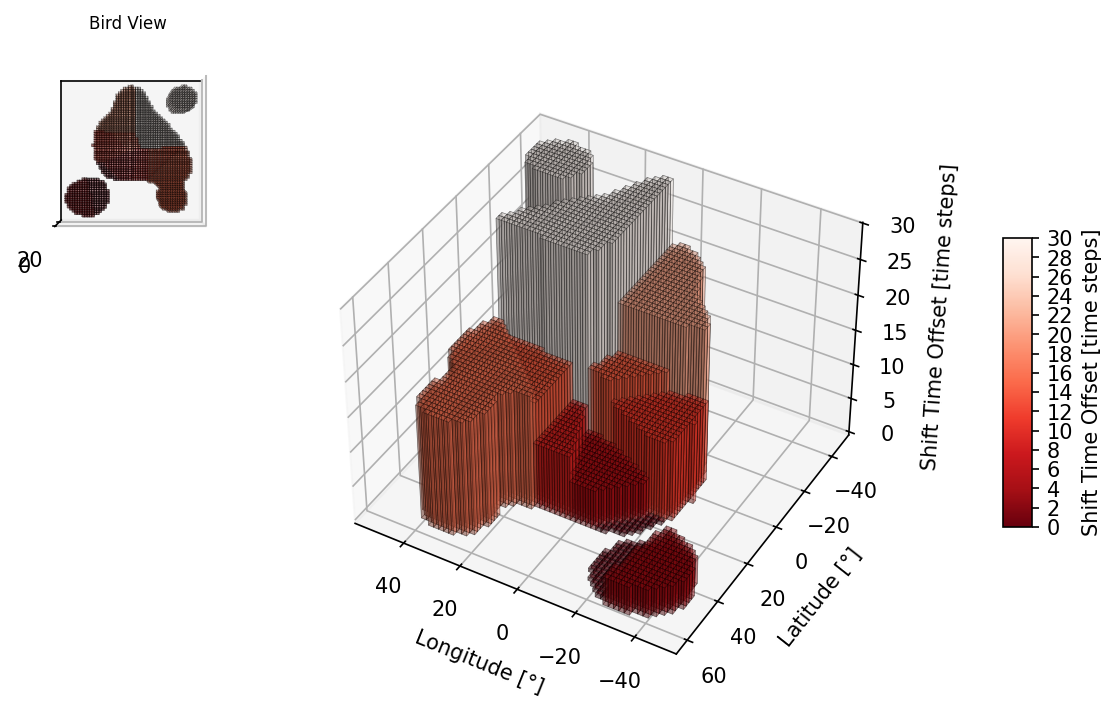

In [7]:
from ponds import BLOB, Propagating

lat_size = 101
lon_size = 201
lats = np.linspace(-90, 90, lat_size)
lons = np.linspace(-180, 180, lon_size)

# Create a mask with a blob shape
cluster = BLOB(
    center_lat=0,
    center_lon=0,
    shape_seed=10,
    size=10,
    goo=1.95,
)
cluster_mask = cluster.make_shape(lats=lats, lons=lons)

corr = Propagating(
    feature_name="central_time",
    n_cells=10,
    corr_seed=3,
    max_offset=30,
)

shift_times = corr.make_feature_offsets(
    cluster_mask,
)

fig, ax = barplot_3D(
    cluster_mask,
    lons,
    lats,
    shift_times,
    alpha=0.3,
    cmap="Reds_r",
)

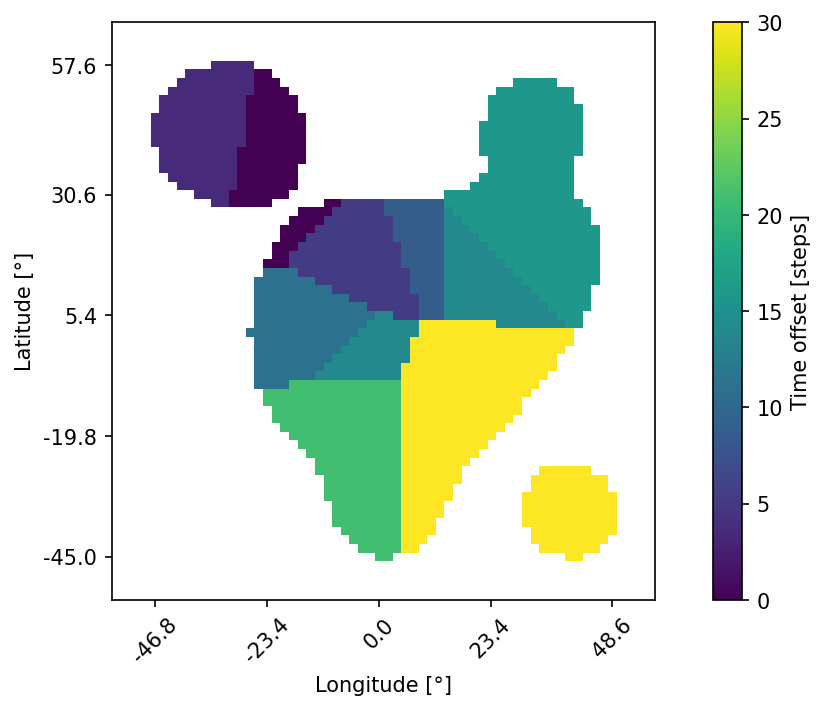

In [8]:
birdview_heatmap(
    cluster_mask,
    shift_times,
)

## Custom Correlation

The user can also specify its own custom correlation mask. This mask needs to be of the same shape as the PONDS grid and can only contain integer values, indicating how many time steps the shift event is set off from the specified `central_time`.

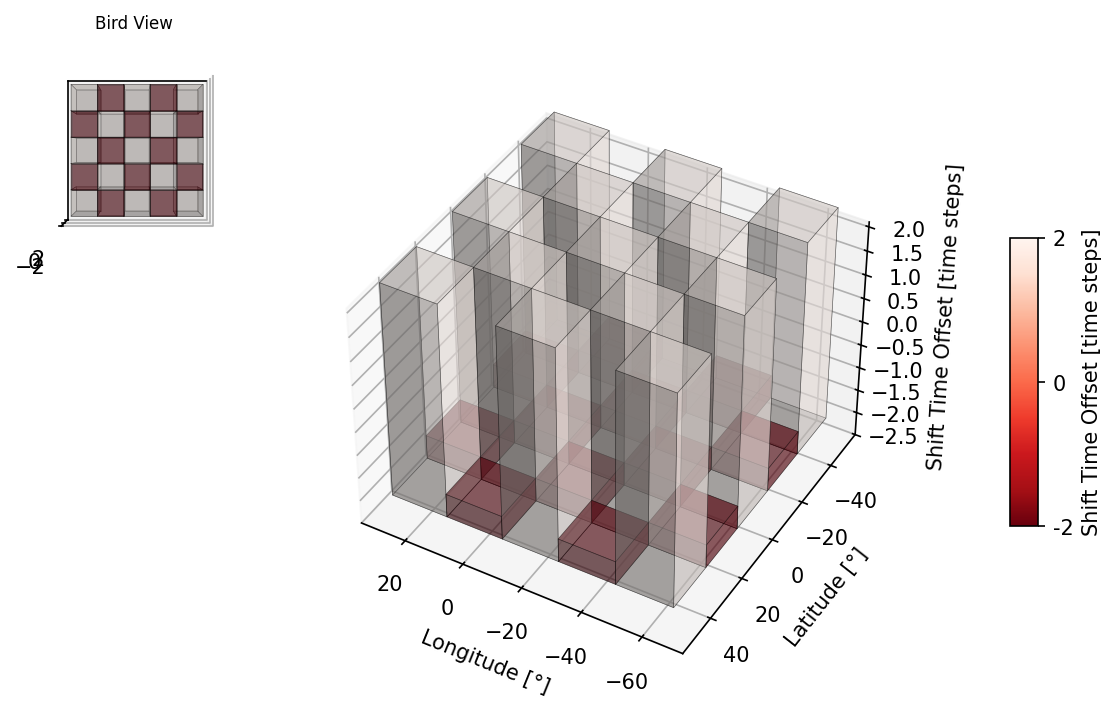

In [11]:
from ponds import Custom
import numpy as np

lat_size = 10
lon_size = 20
lats = np.linspace(-90, 90, lat_size)
lons = np.linspace(-180, 180, lon_size)

custom_corr_mask = np.array(
    [
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 2, -2, 2, -2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, -2, 2, -2, 2, -2, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 2, -2, 2, -2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, -2, 2, -2, 2, -2, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 2, -2, 2, -2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    ],
)
cluster_mask = custom_corr_mask.astype(bool)

corr = Custom(
    feature_name="central_time",
    offset_mask=custom_corr_mask,
)

shift_times = corr.make_feature_offsets(
    cluster_mask,
)

fig, ax = barplot_3D(
    cluster_mask,
    lons,
    lats,
    shift_times,
    alpha=0.4,
    cmap="Reds_r",
)

This function can be used to create very individual kinds of correlations, as shown below.

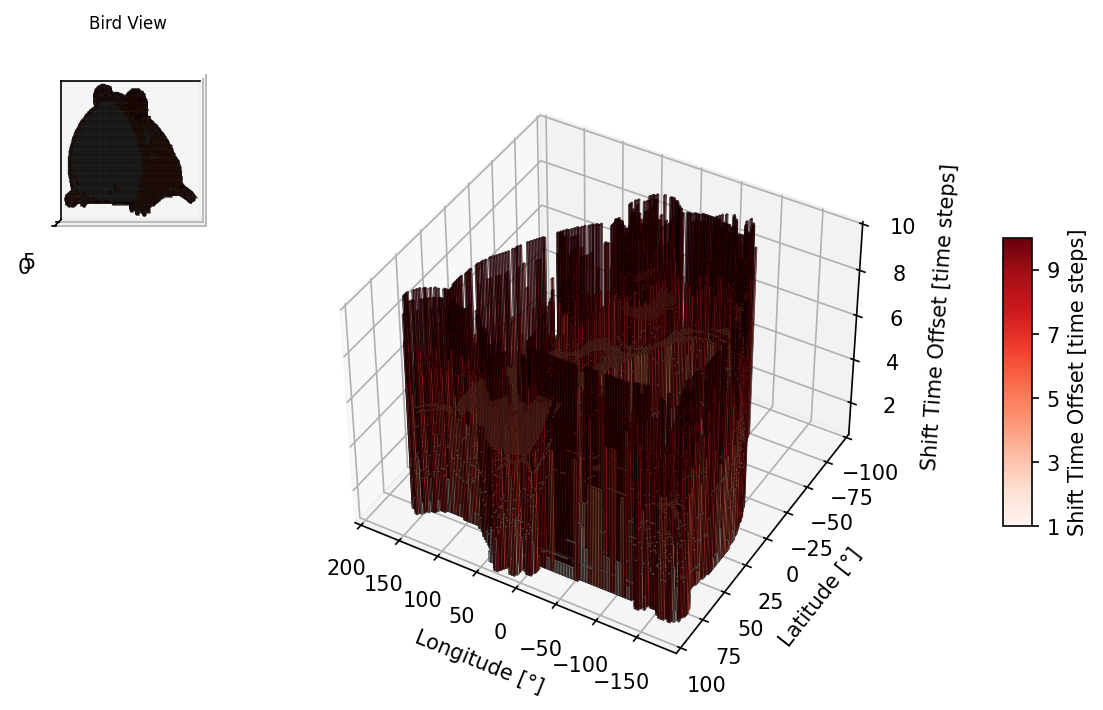

In [13]:
from ponds import Custom
import numpy as np

fp = "test_data/toad_array.csv"
custom_corr_mask = np.loadtxt(fp, delimiter=",", dtype=int)


lat_size = custom_corr_mask.shape[0]
lon_size = custom_corr_mask.shape[1]
lats = np.linspace(-90, 90, lat_size)
lons = np.linspace(-180, 180, lon_size)
cluster_mask = custom_corr_mask.astype(bool)

corr = Custom(
    feature_name="central_time",
    offset_mask=custom_corr_mask,
)

shift_times = corr.make_feature_offsets(
    cluster_mask,
)

fig, ax = barplot_3D(
    cluster_mask,
    lons,
    lats,
    shift_times,
    alpha=0.4,
    cmap="Reds",
    # elev=-90,
    # azim=-90,
)

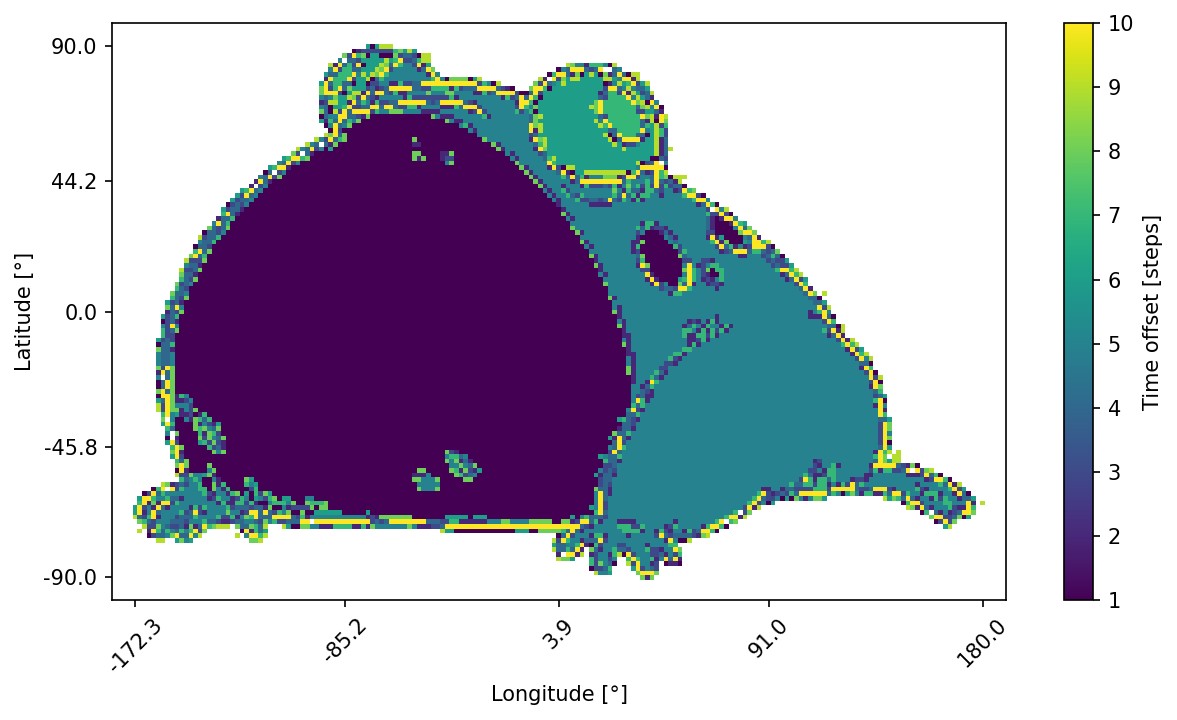

In [14]:
birdview_heatmap(
    np.flip(cluster_mask, axis=(0)),
    np.flip(shift_times, axis=(0)),
)